# 02 Tuning and the final model

Here we compare CatBoost and LightGBM, pick the final model and calibrate it. Only train and validation are used; the test years stay out of it.

Tuning runs on folds that go from past to future inside train: we fit up to 2005, 2009 and 2013 and check on 2006-2009, 2010-2013 and 2014-2017, because random folds do not see how the data changes over time. CatBoost gets 30 Optuna trials and LightGBM, with its native categorical features, gets 12. Both minimize log loss, with at most 500 iterations and early stopping after 50.

For the final fit, the number of trees is the mean best iteration over the time folds. The model is then refitted on all fitting rows and averaged over 5 seeds.

Two rules decide the outcome. Tuned CatBoost replaces the typical settings only if its gain in validation log loss is larger than the spread between seeds. LightGBM becomes the final model if it beats the chosen CatBoost on both the time folds and validation. CatBoost stays in every comparison either way.

Both models are then calibrated with Platt scaling and isotonic regression. The validation expeditions are split into two random halves, and each half is calibrated by what was learned on the other, using non-anomalous rows only. The notebook ends with paired comparisons against the baselines, a check without `ROUTE1` and `AGENCY`, and a look at why LightGBM wins.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import gc
import json
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score

from src import models as M
from src.config import FINAL_MODEL_PATH, TABLES_DIR, TARGET
from src.evaluate import evaluate_views, fmt, paired_difference, plot_calibration, results_table
from src.experiment_log import log_experiment
from src.features import CATEGORICAL
from src.split import dev_split, fit_frame, load_features
from src.style import ORANGE, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
apply_style()
N_BOOT = 1000

In [2]:
df = load_features()
train, val = dev_split(df)
train_fit = fit_frame(train)
clean = ~val["ANOMALOUS_SEASON"].to_numpy()
print(f"train {len(train):,} (fit {len(train_fit):,}) | val {len(val):,} (clean {clean.sum():,})")
print(f"{TARGET}: train {train[TARGET].mean():.3f} | val {val[TARGET].mean():.3f} | val clean {val.loc[clean, TARGET].mean():.3f}")
print(f"model features ({len(M.MODEL_FEATURES)}): YEAR excluded; categorical: {M.cat_names(M.MODEL_FEATURES)}")

train 37,969 (fit 37,448) | val 5,042 (clean 4,236)
MSUCCESS: train 0.383 | val 0.537 | val clean 0.549
model features (34): YEAR excluded; categorical: ['SEX', 'CITIZEN', 'STATUS', 'PEAK_GROUP', 'ROUTE1', 'SEASON', 'HOST', 'AGENCY', 'HIMAL', 'REGION']


In [3]:
N_TRIALS_CB, N_TRIALS_LGBM = 30, 12
STORAGE = "sqlite:///" + (Path(tempfile.gettempdir()) / "himalayan_optuna.db").as_posix()

## 1. CatBoost with Optuna

In [4]:
study_cb = M.tune_catboost(train_fit, n_trials=N_TRIALS_CB, metric="logloss", storage=STORAGE)
trials_cb = study_cb.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).dropna(subset=["value"])
trials_cb.to_csv(TABLES_DIR / "02_optuna_catboost_trials.csv", index=False)
print("best CV log loss:", round(study_cb.best_value, 4))
print(study_cb.best_params)
display(trials_cb.sort_values("value").head(10))

best CV log loss: 0.6361
{'learning_rate': 0.04103897228367933, 'depth': 8, 'l2_leaf_reg': 3.2003280507751035, 'bagging_temperature': 0.43914639935552363, 'random_strength': 0.5298311996977793}


,number,value,params_bagging_temperature,params_depth,params_l2_leaf_reg,params_learning_rate,params_random_strength,user_attrs_mean_best_iteration
19,19,0.636103,0.439146,8,3.200328,0.041039,0.529831,39
11,11,0.636913,0.618612,8,6.939448,0.057978,0.783583,58
25,25,0.637055,0.207324,8,3.967870,0.051770,0.763122,66
27,27,0.638266,0.320462,8,5.217802,0.031631,0.523394,99
16,16,0.638861,0.473541,8,2.976185,0.071806,0.639740,33
20,20,0.638893,0.367311,8,2.221129,0.046339,0.683622,101
12,12,0.639241,0.086885,8,17.527133,0.083324,0.583572,44
22,22,0.639607,0.353010,8,1.111656,0.041156,0.794978,70
13,13,0.639689,0.051696,8,22.323118,0.087234,0.711135,29
21,21,0.639709,0.492474,7,2.258183,0.077163,0.547320,38


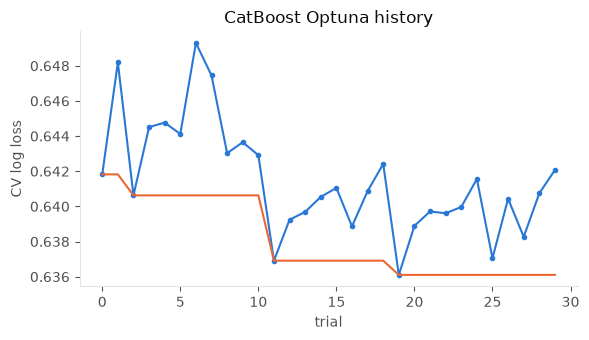

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(trials_cb["number"], trials_cb["value"], "o-", ms=3)
ax.plot(trials_cb["number"], trials_cb["value"].cummin(), color=ORANGE)
ax.set_xlabel("trial")
ax.set_ylabel("CV log loss")
ax.set_title("CatBoost Optuna history")
plt.tight_layout()
save_figure(fig, "02_optuna_catboost_history.png")
plt.show()

In [6]:
cv_typical = M.cv_catboost(train_fit, params=M.DEFAULT_CATBOOST)
iters_typical = int(cv_typical["iterations"].mean())
iters_tuned = study_cb.best_trial.user_attrs["mean_best_iteration"]
print(cv_typical.round(4).to_string())
print(f"typical: CV log loss {cv_typical['log_loss'].mean():.4f}, trees {iters_typical}")
print(f"tuned:   CV log loss {study_cb.best_value:.4f}, trees {iters_tuned}")
cb_default = M.refit_catboost(train_fit, iters_typical, params=M.DEFAULT_CATBOOST)
cb_tuned = M.refit_catboost(train_fit, iters_tuned, params=study_cb.best_params)
p_cb_default, p_cb = cb_default.predict(val), cb_tuned.predict(val)

   log_loss  roc_auc  iterations
0    0.6560   0.6511          16
1    0.6256   0.6955          44
2    0.6429   0.6792          32
typical: CV log loss 0.6415, trees 30
tuned:   CV log loss 0.6361, trees 39


## 2. LightGBM

In [7]:
study_lgbm = M.tune_lightgbm(train_fit, n_trials=N_TRIALS_LGBM, metric="logloss", storage=STORAGE)
trials_lgbm = study_lgbm.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).dropna(subset=["value"])
trials_lgbm.to_csv(TABLES_DIR / "02_optuna_lightgbm_trials.csv", index=False)
lgbm_params = {**study_lgbm.best_params, "subsample_freq": 1}
iters_lgbm = study_lgbm.best_trial.user_attrs["mean_best_iteration"]
print("best CV log loss:", round(study_lgbm.best_value, 4), "| trees:", iters_lgbm)
print(lgbm_params)
lgbm = M.refit_lightgbm(train_fit, iters_lgbm, params=lgbm_params)
p_lgbm = lgbm.predict(val)

best CV log loss: 0.6307 | trees: 176
{'learning_rate': 0.024520114718375053, 'num_leaves': 25, 'min_child_samples': 28, 'colsample_bytree': 0.6626651653816322, 'subsample': 0.6943386448447411, 'reg_lambda': 0.016400705022266843, 'cat_smooth': 59.86629236379356, 'min_data_per_group': 84, 'subsample_freq': 1}


## 3. Comparison on validation

In [8]:
TYPICAL, TUNED, LGBM = "CatBoost typical (5 seeds)", "CatBoost tuned (5 seeds)", "LightGBM tuned (5 seeds)"
preds = {TYPICAL: p_cb_default, TUNED: p_cb, LGBM: p_lgbm}
rows_all, rows_clean = evaluate_views(preds, val, N_BOOT)
rows_models = (rows_all, rows_clean)
print("VAL, all rows")
display(results_table(rows_all))
print("VAL, without anomalous seasons")
display(results_table(rows_clean))

y_val = M.target(val)
seed_table = pd.DataFrame([{"model": name, "seed": seed, "roc_auc": roc_auc_score(y_val, p), "log_loss": log_loss(y_val, p)}
                           for name, model in ((TYPICAL, cb_default), (TUNED, cb_tuned), (LGBM, lgbm))
                           for seed, p in zip(M.SEEDS, (f.predict(val) for f in model.fitted))])
display(seed_table.groupby("model")[["roc_auc", "log_loss"]].agg(["min", "max"]).round(4))
typical_ll = seed_table.loc[seed_table["model"] == TYPICAL, "log_loss"]
seed_spread = typical_ll.max() - typical_ll.min()
gain = log_loss(y_val, p_cb_default) - log_loss(y_val, p_cb)
cb_best = TUNED if gain > seed_spread else TYPICAL
cb_params, cb_iters = (study_cb.best_params, iters_tuned) if cb_best == TUNED else (M.DEFAULT_CATBOOST, iters_typical)
print(f"CatBoost: tuning gain in val log loss {gain:.4f}, spread between seeds {seed_spread:.4f} -> {cb_best}")

scores = pd.DataFrame({"time_folds_log_loss": {TYPICAL: cv_typical["log_loss"].mean(), TUNED: study_cb.best_value, LGBM: study_lgbm.best_value},
                       "val_log_loss": {name: log_loss(y_val, p) for name, p in preds.items()}})
display(scores.round(4))
wins = (scores.loc[LGBM] < scores.loc[cb_best]).all()
best = LGBM if wins else cb_best
print("final model:", best)
assert best == LGBM, "the frozen configuration below describes LightGBM"
final = {"model": "lightgbm", "params": lgbm_params, "iterations": iters_lgbm, "seeds": list(M.SEEDS), "features": list(M.MODEL_FEATURES)}
FINAL_MODEL_PATH.write_text(json.dumps(final, indent=2) + "\n")
del cb_default, cb_tuned
_ = gc.collect()

VAL, all rows


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
CatBoost typical (5 seeds),"0.689 [0.657, 0.721]","0.224 [0.216, 0.232]","0.639 [0.622, 0.657]",5042,0.491668
CatBoost tuned (5 seeds),"0.693 [0.662, 0.724]","0.224 [0.217, 0.231]","0.639 [0.625, 0.653]",5042,0.492163
LightGBM tuned (5 seeds),"0.712 [0.683, 0.739]","0.216 [0.209, 0.224]","0.622 [0.605, 0.640]",5042,0.496317


VAL, without anomalous seasons


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
CatBoost typical (5 seeds),"0.711 [0.681, 0.741]","0.219 [0.211, 0.227]","0.628 [0.611, 0.646]",4236,0.492539
CatBoost tuned (5 seeds),"0.714 [0.683, 0.744]","0.219 [0.212, 0.225]","0.628 [0.614, 0.642]",4236,0.495344
LightGBM tuned (5 seeds),"0.737 [0.711, 0.762]","0.210 [0.202, 0.218]","0.608 [0.591, 0.625]",4236,0.491332


roc_auc         log_loss        
                               min     max      min     max
model                                                      
CatBoost tuned (5 seeds)    0.6847  0.6960   0.6384  0.6419
CatBoost typical (5 seeds)  0.6821  0.6929   0.6385  0.6423
LightGBM tuned (5 seeds)    0.7098  0.7115   0.6213  0.6230

CatBoost: tuning gain in val log loss 0.0006, spread between seeds 0.0038 -> CatBoost typical (5 seeds)


,time_folds_log_loss,val_log_loss
CatBoost typical (5 seeds),0.6415,0.6393
CatBoost tuned (5 seeds),0.6361,0.6388
LightGBM tuned (5 seeds),0.6307,0.6219


final model: LightGBM tuned (5 seeds)


## 4. Calibration

In [9]:
fit_rows = clean
def calibrations(p):
    return {"before": p,
            "Platt": M.crossfit_calibrate(val, p, "platt", fit_rows=fit_rows),
            "isotonic": M.crossfit_calibrate(val, p, "isotonic", fit_rows=fit_rows)}
cal, cal_cb = calibrations(preds[best]), calibrations(preds[cb_best])
rows_all_c, rows_clean_c = evaluate_views({**{f"{best} | {k}": v for k, v in cal.items()},
                                           **{f"{cb_best} | {k}": v for k, v in cal_cb.items()}}, val, N_BOOT)
print("VAL, all rows")
display(results_table(rows_all_c))
print("VAL, without anomalous seasons")
display(results_table(rows_clean_c))

VAL, all rows


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
LightGBM tuned (5 seeds) | before,"0.712 [0.683, 0.739]","0.216 [0.209, 0.224]","0.622 [0.605, 0.640]",5042,0.496317
LightGBM tuned (5 seeds) | Platt,"0.712 [0.684, 0.739]","0.216 [0.206, 0.225]","0.620 [0.597, 0.642]",5042,0.555649
LightGBM tuned (5 seeds) | isotonic,"0.709 [0.682, 0.736]","0.217 [0.207, 0.226]","0.625 [0.600, 0.649]",5042,0.554180
CatBoost typical (5 seeds) | before,"0.689 [0.657, 0.721]","0.224 [0.216, 0.232]","0.639 [0.622, 0.657]",5042,0.491668
CatBoost typical (5 seeds) | Platt,"0.689 [0.658, 0.720]","0.223 [0.213, 0.232]","0.635 [0.614, 0.657]",5042,0.549291
CatBoost typical (5 seeds) | isotonic,"0.684 [0.653, 0.715]","0.224 [0.214, 0.233]","0.640 [0.618, 0.662]",5042,0.548825


VAL, without anomalous seasons


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
LightGBM tuned (5 seeds) | before,"0.737 [0.711, 0.762]","0.210 [0.202, 0.218]","0.608 [0.591, 0.625]",4236,0.491332
LightGBM tuned (5 seeds) | Platt,"0.737 [0.711, 0.762]","0.206 [0.197, 0.215]","0.598 [0.577, 0.619]",4236,0.550062
LightGBM tuned (5 seeds) | isotonic,"0.734 [0.708, 0.759]","0.207 [0.198, 0.216]","0.603 [0.580, 0.625]",4236,0.548026
CatBoost typical (5 seeds) | before,"0.711 [0.681, 0.741]","0.219 [0.211, 0.227]","0.628 [0.611, 0.646]",4236,0.492539
CatBoost typical (5 seeds) | Platt,"0.709 [0.679, 0.740]","0.216 [0.206, 0.226]","0.620 [0.599, 0.644]",4236,0.550645
CatBoost typical (5 seeds) | isotonic,"0.706 [0.677, 0.736]","0.217 [0.207, 0.227]","0.624 [0.602, 0.648]",4236,0.551144


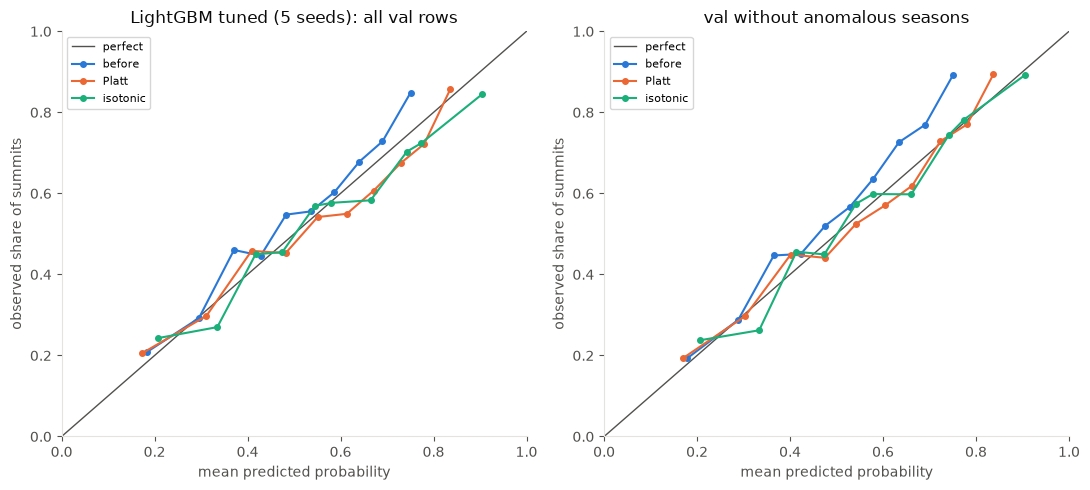

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_calibration(val[TARGET], cal, ax=axes[0], title=f"{best}: all val rows")
plot_calibration(val.loc[clean, TARGET], {k: v[clean] for k, v in cal.items()}, ax=axes[1], title="val without anomalous seasons")
plt.tight_layout()
save_figure(fig, "02_calibration_before_after.png")
plt.show()

## 5. Paired comparison
All validation rows, with whole expeditions resampled.

In [11]:
p_lr = M.fit_logreg(train_fit).predict(val)
p_rule = M.PeakSeasonRate().fit(train_fit).predict(val)
others = {"logreg": p_lr, "peak x season rule": p_rule, TYPICAL: p_cb_default, TUNED: p_cb}
comparison = pd.DataFrame([{"comparison": f"{best} minus {name}", **fmt(paired_difference(val[TARGET], preds[best], p, val["EXPID"], N_BOOT), digits=4)}
                           for name, p in others.items()]).set_index("comparison")
comparison.to_csv(TABLES_DIR / "02_paired_differences.csv")
display(comparison)

,roc_auc,brier,log_loss
comparison,,,
LightGBM tuned (5 seeds) minus logreg,"0.0257 [0.0112, 0.0392]","-0.0117 [-0.0182, -0.0052]","-0.0340 [-0.0513, -0.0169]"
LightGBM tuned (5 seeds) minus peak x season rule,"0.1108 [0.0846, 0.1390]","-0.0331 [-0.0410, -0.0253]","-0.0708 [-0.0874, -0.0538]"
LightGBM tuned (5 seeds) minus CatBoost typical (5 seeds),"0.0225 [0.0081, 0.0377]","-0.0078 [-0.0115, -0.0039]","-0.0175 [-0.0261, -0.0088]"
LightGBM tuned (5 seeds) minus CatBoost tuned (5 seeds),"0.0183 [0.0033, 0.0342]","-0.0075 [-0.0112, -0.0036]","-0.0169 [-0.0252, -0.0083]"


## 6. Without `ROUTE1` and `AGENCY`
The final model keeps both features. Here we only see how much the metrics move without them, on the time folds and on validation.

In [12]:
SLIM = [f for f in M.MODEL_FEATURES if f not in ("ROUTE1", "AGENCY")]
families = (("LightGBM", M.cv_lightgbm, M.refit_lightgbm, lgbm_params, preds[best]),
            ("CatBoost", M.cv_catboost, M.refit_catboost, cb_params, preds[cb_best]))
rows, slim_preds, slim_diffs = [], {}, []
for family, cv_fn, refit_fn, params, p_base in families:
    slim_trees = []
    for name, features in (("all features", M.MODEL_FEATURES), ("without ROUTE1/AGENCY", SLIM)):
        for seed in (42, 1, 2):
            cv = cv_fn(train_fit, params=params, features=features, seed=seed)
            rows.append({"model": family, "features": name, "seed": seed, "cv_roc_auc": cv["roc_auc"].mean(), "cv_log_loss": cv["log_loss"].mean()})
            if features is SLIM:
                slim_trees.append(cv["iterations"].mean())
    p_slim = refit_fn(train_fit, int(np.mean(slim_trees)), params=params, features=SLIM).predict(val)
    slim_preds[f"{family} without ROUTE1/AGENCY (5 seeds)"] = p_slim
    slim_diffs.append({"comparison": f"{family}: without minus with ROUTE1/AGENCY", **fmt(paired_difference(val[TARGET], p_slim, p_base, val["EXPID"], N_BOOT), digits=4)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(TABLES_DIR / "02_sensitivity_route_agency.csv", index=False)
display(sensitivity.groupby(["model", "features"])[["cv_roc_auc", "cv_log_loss"]].mean().round(4))
rows_slim_all, rows_slim_clean = evaluate_views(slim_preds, val, N_BOOT)
print("VAL, all rows")
display(results_table(rows_slim_all))
print("VAL, without anomalous seasons")
display(results_table(rows_slim_clean))
display(pd.DataFrame(slim_diffs).set_index("comparison"))

cv_roc_auc  cv_log_loss
model    features                                      
CatBoost all features               0.6765       0.6413
         without ROUTE1/AGENCY      0.6890       0.6338
LightGBM all features               0.6916       0.6304
         without ROUTE1/AGENCY      0.6934       0.6289

VAL, all rows


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
LightGBM without ROUTE1/AGENCY (5 seeds),"0.711 [0.682, 0.738]","0.217 [0.209, 0.225]","0.622 [0.605, 0.640]",5042,0.501169
CatBoost without ROUTE1/AGENCY (5 seeds),"0.697 [0.668, 0.726]","0.221 [0.213, 0.229]","0.632 [0.614, 0.650]",5042,0.490744


VAL, without anomalous seasons


,ROC AUC,Brier,Log loss,n,mean_p
model,,,,,
LightGBM without ROUTE1/AGENCY (5 seeds),"0.738 [0.713, 0.763]","0.210 [0.202, 0.217]","0.607 [0.591, 0.624]",4236,0.496184
CatBoost without ROUTE1/AGENCY (5 seeds),"0.718 [0.688, 0.746]","0.215 [0.207, 0.223]","0.620 [0.602, 0.637]",4236,0.494414


,roc_auc,brier,log_loss
comparison,,,
LightGBM: without minus with ROUTE1/AGENCY,"-0.0005 [-0.0065, 0.0058]","0.0002 [-0.0016, 0.0019]","0.0006 [-0.0032, 0.0044]"
CatBoost: without minus with ROUTE1/AGENCY,"0.0078 [-0.0020, 0.0179]","-0.0030 [-0.0059, -0.0004]","-0.0070 [-0.0137, -0.0010]"


## 7. Why LightGBM wins
We keep the same training recipe and change one setting at a time, to see whether the gain comes from the library, from tuning in general or from how categories are handled.

In [13]:
smoothing = {k: lgbm_params[k] for k in ("cat_smooth", "min_data_per_group")}
numeric_only = [f for f in M.MODEL_FEATURES if f not in CATEGORICAL]
variants = {"default LightGBM": ({}, M.MODEL_FEATURES),
            "default + category smoothing as tuned": (smoothing, M.MODEL_FEATURES),
            "tuned LightGBM": (lgbm_params, M.MODEL_FEATURES),
            "tuned, weak category smoothing": ({**lgbm_params, "cat_smooth": 1.0, "min_data_per_group": 1}, M.MODEL_FEATURES),
            "tuned, no row and column sampling": ({**lgbm_params, "colsample_bytree": 1.0, "subsample": 1.0, "subsample_freq": 0}, M.MODEL_FEATURES),
            "tuned, no categorical features": (lgbm_params, numeric_only)}
rows = []
for name, (params, features) in variants.items():
    cv = pd.concat([M.cv_lightgbm(train_fit, params=params, features=features, seed=s) for s in (42, 1, 2)])
    p = M.refit_lightgbm(train_fit, max(int(cv["iterations"].mean()), 1), params=params, features=features).predict(val)
    rows.append({"variant": name, "trees": int(cv["iterations"].mean()), "cv_log_loss": cv["log_loss"].mean(), "cv_roc_auc": cv["roc_auc"].mean(),
                 "val_roc_auc": roc_auc_score(y_val, p), "val_log_loss": log_loss(y_val, p)})
why_lgbm = pd.DataFrame(rows).set_index("variant")
why_lgbm.to_csv(TABLES_DIR / "02_why_lightgbm.csv")
display(why_lgbm.round(4))
print("levels in fitting rows:", {col: M._cat(train_fit[col]).nunique() for col in CATEGORICAL})

,trees,cv_log_loss,cv_roc_auc,val_roc_auc,val_log_loss
variant,,,,,
default LightGBM,19,0.6467,0.6691,0.6900,0.6411
default + category smoothing as tuned,32,0.6352,0.6840,0.7044,0.6270
tuned LightGBM,178,0.6304,0.6916,0.7119,0.6216
"tuned, weak category smoothing",87,0.6445,0.6740,0.6782,0.6460
"tuned, no row and column sampling",150,0.6332,0.6872,0.7066,0.6259
"tuned, no categorical features",143,0.6322,0.6887,0.6893,0.6360


levels in fitting rows: {'SEX': 2, 'CITIZEN': 188, 'STATUS': 133, 'PEAK_GROUP': 20, 'ROUTE1': 599, 'SEASON': 4, 'HOST': 4, 'AGENCY': 672, 'HIMAL': 20, 'REGION': 7}


## 8. Experiment log

In [14]:
every = {**{r["model"]: (r["_res"], k["_res"]) for r, k in zip(*rows_models)},
         **{r["model"]: (r["_res"], k["_res"]) for r, k in zip(rows_all_c, rows_clean_c)},
         **{r["model"]: (r["_res"], k["_res"]) for r, k in zip(rows_slim_all, rows_slim_clean)}}
notes = {TYPICAL: f"learning rate 0.1, {iters_typical} trees from time folds, refit on all fitting rows; CV {cv_typical['log_loss'].mean():.4f}.",
         TUNED: f"Optuna {N_TRIALS_CB} trials on time folds, {iters_tuned} trees, refit on all fitting rows; CV {study_cb.best_value:.4f}.",
         LGBM: f"Final model. Optuna {N_TRIALS_LGBM} trials on time folds, {iters_lgbm} trees, refit on all fitting rows; CV {study_lgbm.best_value:.4f}.",
         **{name: "Sensitivity check only; the model keeps these features." for name in slim_preds}}
for name, (ra, rc) in every.items():
    note = notes.get(name, "Calibrated on the other half of val (out-of-fold), anomalous rows excluded from calibrator fit.")
    log_experiment(name, ra, rc, note)
print("experiment log updated")

experiment log updated
